# Seidel aberrations surface by surface: correction and tension in Caldwell's KrF lens

The third order (Seidel) aberrations of a centred system are sums over its
surfaces. Every surface adds its own spherical aberration $S_I$, coma
$S_{II}$, astigmatism $S_{III}$, Petzval curvature $S_{IV}$ and distortion
$S_V$, computed from the paraxial marginal ray (height $y$, refraction
invariant $A = n i$) and the paraxial chief ray ($\bar y$, $\bar A = n \bar i$)
(Welford):

$$
S_I = -A^2 y\,\Delta\!\left(\tfrac{u}{n}\right),\quad
S_{II} = -A\bar A y\,\Delta\!\left(\tfrac{u}{n}\right),\quad
S_{III} = -\bar A^2 y\,\Delta\!\left(\tfrac{u}{n}\right),\quad
S_{IV} = -H^2 c\,\Delta\!\left(\tfrac{1}{n}\right),\quad
S_V = \tfrac{\bar A}{A}(S_{III} + S_{IV}),
$$

plus terms $8 a_4 \Delta n$ times $y^4$, $y^3\bar y$, … for the departure of a
conic or asphere from its vertex sphere. The primary colours are
$C_I = A y\,\Delta(\delta n/n)$ (axial) and $C_{II} = \bar A y\,\Delta(\delta n/n)$
(lateral). Only the *sums* are properties of the lens. The single terms
describe how the correction is shared between the surfaces. A well corrected
lens has small sums. They can be small because every term is small (a relaxed
design) or because large terms of opposite sign cancel (a tense design).
Tense designs are sensitive to manufacturing and assembly errors, because an
error in one surface upsets a large term that nothing else balances any more.

This notebook takes Caldwell's all fused silica KrF projection lens
(`raytrace.caldwell_krf_lens()`: 21 elements, NA 0.56, 4x, 1 m, telecentric on
both sides) and

1. collects its first order data: total power, powers of the surfaces and
   elements, the share of each surface in the power, the Petzval sum and the
   third order image surfaces (`System.power()`, `surface_powers()`,
   `power_contributions()`, `elements()`, `element_powers()`, `third_order()`),
2. plots the five Seidel terms surface by surface (`System.seidel()`) and
   explains which surfaces and groups introduce and which compensate each
   aberration,
3. follows the running sums through the lens,
4. compares the Seidel sums with the real ray wavefront (third against higher
   orders),
5. quantifies the *tension* of the correction and shows what it costs, with
   element decentres traced with real rays,
6. looks at the primary colour (`System.chromatic_seidel()`), which a lens made
   of one glass cannot correct.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

lens = rt.caldwell_krf_lens()
WL = lens.wavelength
p = lens.paraxial()
sd = lens.seidel()
els = lens.elements()
phi_el = lens.element_powers()
n_surf = len(lens.surfaces)

## 1. First order: power, Petzval sum and the five groups

The lens has the classical form of a lithography lens: positive groups where
the marginal ray is high (*bulges*) and negative groups where it is low
(*waists*). The listing gives every element with its focal length in air and
the marginal and chief ray heights at its first surface.

In [2]:
ym, yc = p.marginal[:, 0], p.chief[:, 0]
print(f"power of the lens   {lens.power():.6f} 1/mm  (efl {p.efl:.1f} mm, magnification {p.magnification:.4f}, NA {p.na:.3f})")
print(f"Lagrange invariant  H = {p.lagrange:.4f} mm, stop at surface {lens.stop_index + 1}")
print(f"sum of the surface power contributions y_i*phi_i/y_1: {lens.power_contributions().sum():.6f} 1/mm")
print()
print(" el  surfaces   f [mm]    y [mm]  ybar [mm]")
for k, ((a, b), f) in enumerate(zip(els, phi_el)):
    print(f"{k + 1:3d}   {a + 1:2d}-{b + 1:2d}  {1/f:8.0f}  {ym[a]:8.1f}  {yc[a]:8.1f}")

power of the lens   0.000467 1/mm  (efl 2139.5 mm, magnification -0.2500, NA 0.536)
Lagrange invariant  H = -6.2702 mm, stop at surface 30
sum of the surface power contributions y_i*phi_i/y_1: 0.000467 1/mm

 el  surfaces   f [mm]    y [mm]  ybar [mm]
  1    1- 2       598      14.5      46.3
  2    3- 4       278      17.5      46.9
  3    5- 6      -585      20.2      37.6
  4    7- 8      -293      21.4      33.4
  5    9-10      -414      26.2      30.4
  6   11-12      -141      34.3      29.9
  7   13-14       301      41.7      33.3
  8   15-16       326      52.9      38.4
  9   17-18       544      59.4      39.8
 10   19-20       642      60.2      38.4
 11   21-22       524      58.9      35.9
 12   23-24      -180      40.3      15.7
 13   25-26      -220      39.2      10.6
 14   27-28      -142      50.4       3.1
 15   29-30       535      60.4       1.3
 16   31-32       295      70.4      -0.1
 17   33-34       452      81.0      -2.5
 18   35-36       566      82.3   

By the signs of the element powers the lens splits into five groups:

| group | elements | surfaces | powers | role |
|---|---|---|---|---|
| G1 | 1–2 | 1–4 | + | front field group, large $\bar y$: telecentricity on the reticle side, distortion |
| G2 | 3–6 | 5–12 | − | first waist |
| G3 | 7–11 | 13–22 | + | first bulge |
| G4 | 12–14 | 23–28 | − | second waist |
| G5 | 15–21 | 29–42 | + (20: weak −) | aperture group with the stop (surface 30) and the wafer side |

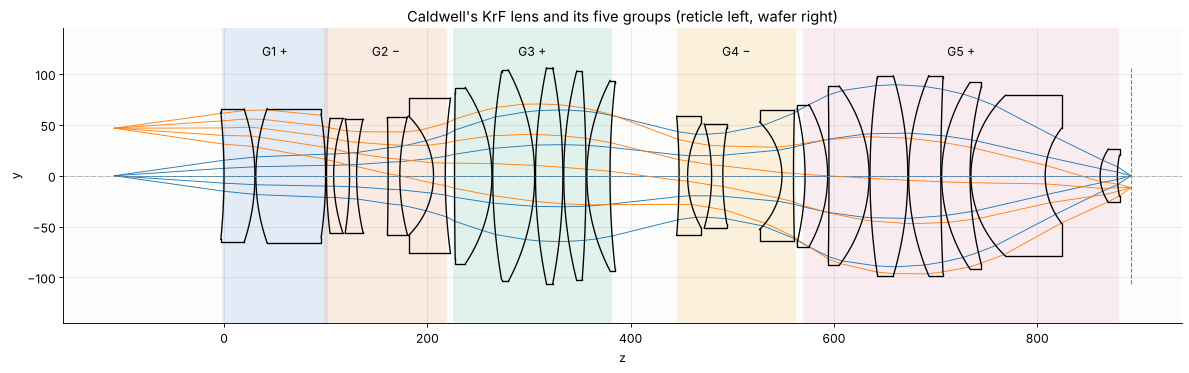

In [3]:
GROUPS = [("G1 +", 0, 1), ("G2 −", 2, 5), ("G3 +", 6, 10), ("G4 −", 11, 13), ("G5 +", 14, 20)]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
surf_group = np.zeros(n_surf, dtype=int)
for g, (_, e0, e1) in enumerate(GROUPS):
    surf_group[els[e0][0]:els[e1][1] + 1] = g
surf_color = [COLORS[g] for g in surf_group]
idx = np.arange(1, n_surf + 1)

fig, ax = plt.subplots(figsize=(15, 4.8))
lens.draw(ax, fields=[0.0, lens.max_field], n_rays=5)
z0 = lens.vertex_z
for g, (name, e0, e1) in enumerate(GROUPS):
    a, b = els[e0][0], els[e1][1]
    ax.axvspan(z0[a] - 2, z0[b] + 2, color=COLORS[g], alpha=0.12, lw=0)
    ax.text((z0[a] + z0[b])/2, 118, name, ha="center", fontsize=11)
ax.set_title("Caldwell's KrF lens and its five groups (reticle left, wafer right)")
fig.tight_layout()

### Power against Petzval sum

A surface contributes $y_i\varphi_i/y_1$ to the power of the lens but
$\varphi_i/(n n')$ to the Petzval sum, *independent of the ray height*
(Petzval's theorem). That is the reason for the waists: a negative element
where the marginal ray is low costs little power, but subtracts its full
Petzval contribution. Summed over the elements, the positive groups provide
the power, and the waists cancel their Petzval curvature:

positive elements: power share +13.77 /m, Petzval +22.39 /m
negative elements: power share -13.30 /m, Petzval -22.38 /m
Petzval radius -205 m, sagittal -81 m, tangential -36 m, medial -50 m
over the image field (radius 11.70 mm) the medial surface departs by -1362 nm from the plane
third order distortion at the edge of the field: -14.2 ppm = -166 nm


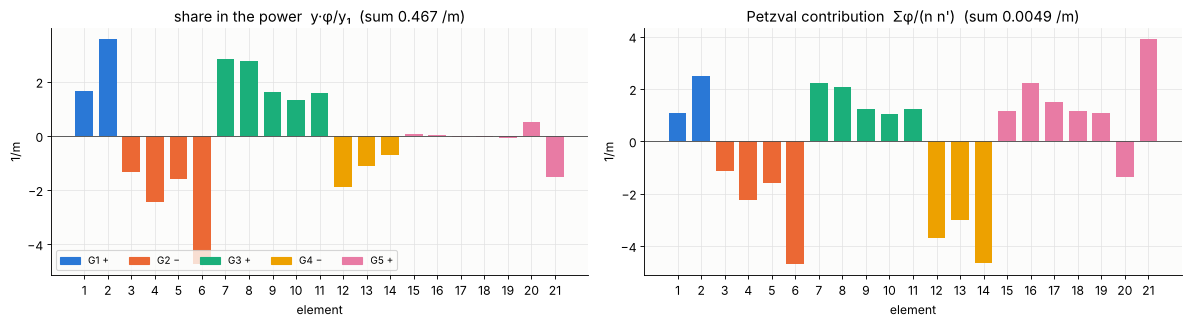

In [4]:
contrib = lens.power_contributions()
petz = lens.surface_powers()/(lens.n*lens.sigma)[:-1]/(lens.n*lens.sigma)[1:]
el_contrib = np.array([contrib[a:b + 1].sum() for a, b in els])
el_petz = np.array([petz[a:b + 1].sum() for a, b in els])
el_color = [COLORS[surf_group[a]] for a, _ in els]
t3 = lens.third_order()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharex=True)
e_idx = np.arange(1, len(els) + 1)
axes[0].bar(e_idx, 1e3*el_contrib, color=el_color, width=0.75)
axes[0].set_title(f"share in the power  y·φ/y₁  (sum {1e3*lens.power():.3f} /m)")
axes[1].bar(e_idx, 1e3*el_petz, color=el_color, width=0.75)
axes[1].set_title(f"Petzval contribution  Σφ/(n n')  (sum {1e3*t3.petzval_sum:.4f} /m)")
for ax in axes:
    ax.set_xlabel("element")
    ax.set_ylabel("1/m")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_xticks(e_idx)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS]
axes[0].legend(handles, [g[0] for g in GROUPS], ncol=5, fontsize=9, loc="lower left")
fig.tight_layout()

print(f"positive elements: power share {1e3*el_contrib[phi_el > 0].sum():+.2f} /m, Petzval {1e3*el_petz[phi_el > 0].sum():+.2f} /m")
print(f"negative elements: power share {1e3*el_contrib[phi_el < 0].sum():+.2f} /m, Petzval {1e3*el_petz[phi_el < 0].sum():+.2f} /m")
print(f"Petzval radius {t3.petzval_radius/1e3:.0f} m, sagittal {t3.sagittal_radius/1e3:.0f} m, "
      f"tangential {t3.tangential_radius/1e3:.0f} m, medial {t3.medial_radius/1e3:.0f} m")
print(f"over the image field (radius {abs(p.image_height):.2f} mm) the medial surface departs by "
      f"{1e6*p.image_height**2/(2*t3.medial_radius):.0f} nm from the plane")
print(f"third order distortion at the edge of the field: {1e6*t3.distortion:.1f} ppm = "
      f"{1e6*t3.distortion*abs(p.image_height):.0f} nm")

The negative elements take away only a fraction of the power of the positive
ones, but nearly all of their Petzval sum. What remains is a Petzval radius of
about 200 m. The astigmatism (section 2) bends the sagittal and tangential
surfaces more strongly (81 m and 36 m). In third order, the medial surface
departs by 1.4 µm from the plane at the edge of the field, more than the depth
of focus. The real lens balances this against higher order field curvature
(section 4).

## 2. The Seidel terms surface by surface

`System.seidel()` returns the contributions `S` (one row per surface) and,
in `W`, the same in waves as the wavefront coefficients
$W_{040} = -S_I/8$, $W_{131} = -S_{II}/2$, $W_{222} = -S_{III}/2$,
$W_{220} = -(S_{III} + S_{IV})/4$, $W_{311} = -S_V/2$ (full aperture, full
field; negative $W_{040}$ = undercorrected, see the conventions of
`raytrace`). The Petzval term is plotted as $-S_{IV}/4$ in waves, the
curvature part of $W_{220}$.

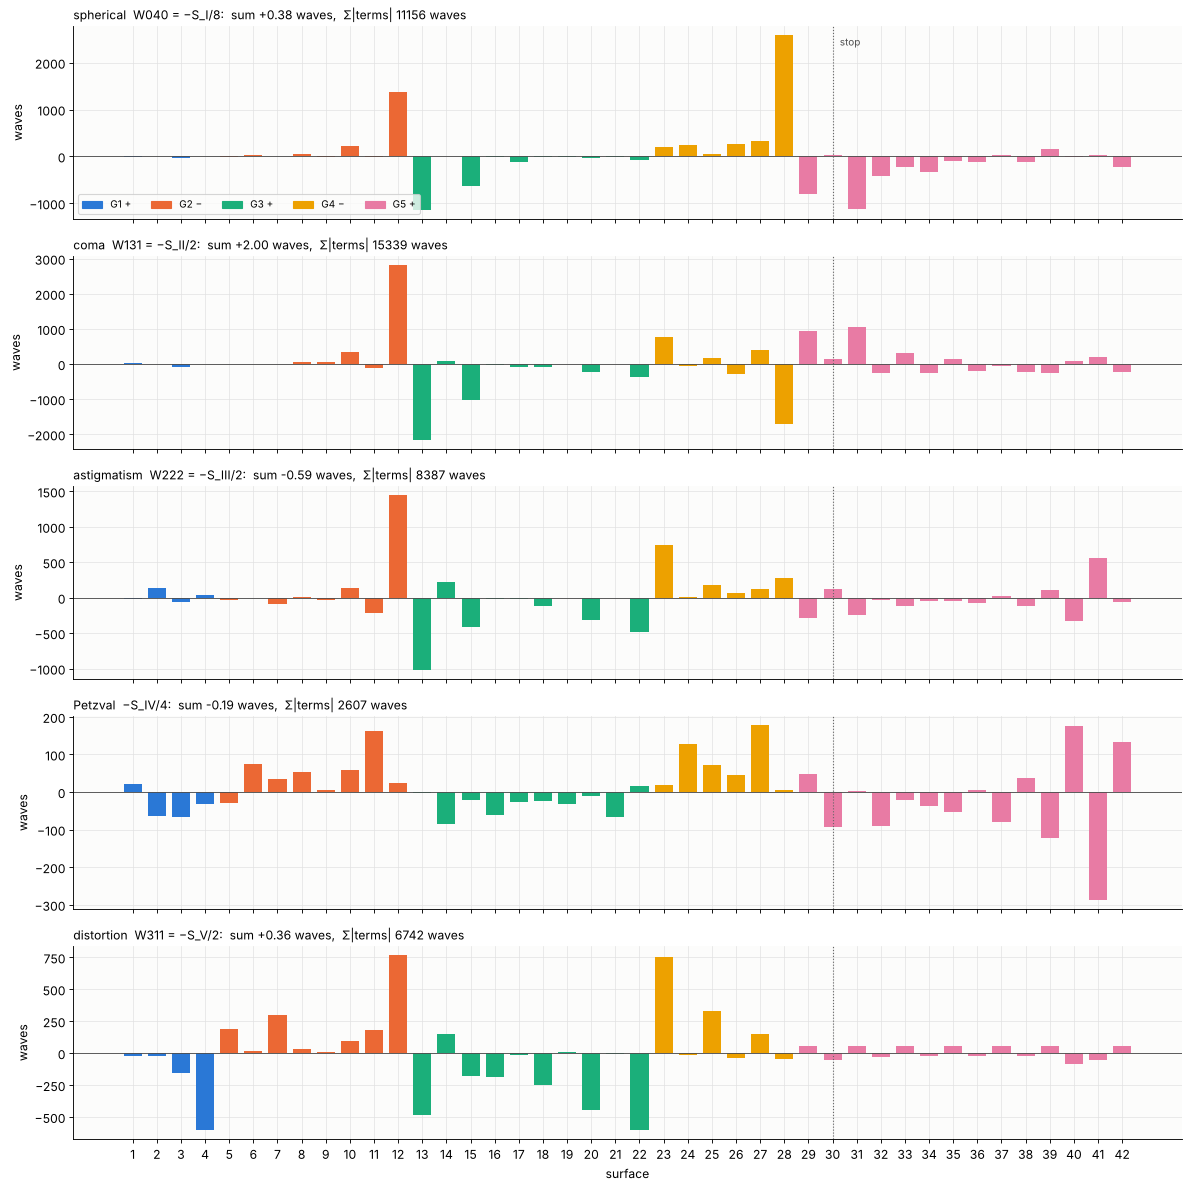

In [5]:
names = ["spherical  W040 = −S_I/8", "coma  W131 = −S_II/2", "astigmatism  W222 = −S_III/2",
         "Petzval  −S_IV/4", "distortion  W311 = −S_V/2"]
k_w = np.array([-1/8, -1/2, -1/2, -1/4, -1/2])/WL
Wsurf = sd.S*k_w
Wtot = sd.total*k_w

fig, axes = plt.subplots(5, 1, figsize=(15, 15), sharex=True)
for j, ax in enumerate(axes):
    ax.bar(idx, Wsurf[:, j], color=surf_color, width=0.75)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.axvline(lens.stop_index + 1, color="0.4", ls=":", lw=1)
    ax.set_ylabel("waves")
    ax.set_title(f"{names[j]}:  sum {Wtot[j]:+.2f} waves,  Σ|terms| {np.abs(Wsurf[:, j]).sum():.0f} waves",
                 loc="left", fontsize=11)
axes[0].text(lens.stop_index + 1.3, 0.85*axes[0].get_ylim()[1], "stop", fontsize=9, color="0.3")
axes[0].legend(handles, [g[0] for g in GROUPS], ncol=5, fontsize=9, loc="lower left")
axes[-1].set_xlabel("surface")
axes[-1].set_xticks(idx)
fig.tight_layout()

In [6]:
print("sums per group in waves (full aperture, full field):")
print(f"{'':6s}" + "".join(f"{n.split()[0]:>14s}" for n in names))
for g, (name, e0, e1) in enumerate(GROUPS):
    a, b = els[e0][0], els[e1][1] + 1
    print(f"{name:6s}" + "".join(f"{v:14.0f}" for v in Wsurf[a:b].sum(axis=0)))
print(f"{'total':6s}" + "".join(f"{v:14.2f}" for v in Wtot))

sums per group in waves (full aperture, full field):
           spherical          coma   astigmatism       Petzval    distortion
G1 +             -31           -66            95          -141          -799
G2 −            1633          3173          1236           383          1594
G3 +           -2027         -3865         -2161          -309         -2006
G4 −            3661          -673          1394           449          1127
G5 +           -3235          1433          -564          -383            84
total           0.38          2.00         -0.59         -0.19          0.36


### Who introduces and who compensates

**Spherical aberration.** Surfaces that bend the marginal ray towards the
axis undercorrect ($W_{040} < 0$). G3 and G5 carry most of the power at large
$y$ and produce about −2000 and −3200 waves. The overcorrection comes from the
two strongest negative elements, 6 (R = −82 mm in front, surfaces 11/12) and
14 (R = −75 mm in front, surfaces 27/28). Their concave front surfaces turn
the beam strongly outwards, but they meet it at moderate incidence and
contribute little themselves. The large terms are at their nearly flat rear
surfaces 12 (R = +570 mm) and 28 (R = +2319 mm). There the marginal ray leaves
the glass at the steepest angles in the whole lens (slopes 0.45 and 0.54 behind
them), with large $A$, and $S_I \propto A^2$: +1380 and +2600 waves. Their
partners are the equally flat front faces of the next positive elements, 13
(R = 5524 mm, −1150 waves), 29 and 31 (−790 and −1120 waves). Each of these
pairs is a strong *air lens* between two flat faces. Such air spaces at the
waists, with a steep marginal ray, are how a lens with spherical surfaces
only gets enough overcorrection.

**Coma and distortion** change sign with $\bar y$. The chief ray crosses the
axis at the stop (surface 30), so a surface in front of the stop and a
similar one behind it give contributions of opposite sign. This is the
*symmetry principle* (Kingslake and Johnson): a system symmetric about
its stop has no coma, distortion or lateral colour. Caldwell's lens is far
from symmetric (4x), but the same mechanism is used. In front of the stop,
the air lens 12/13 makes coma pairs of opposite sign (+2830 and −2170 waves),
and G2 (+3170) and G3 (−3870) nearly cancel. The remaining −700 waves of G1 to
G3 and the −670 of G4 (surface 28: −1700) are balanced by G5 behind the stop
(+1430, mostly surfaces 29 and 31, where $\bar y$ has just changed sign).
Distortion grows with $\bar y$ and is made in front of the stop, where the
chief ray is high. G1, the field lenses (large $\bar y$, small $y$), gives
−800 waves and G3 −2000 waves. The negative G2 (+1600) and G4 (+1130) cancel
them. G5, near the stop with a small $\bar y$, contributes almost nothing.

**Astigmatism** is the slowest varying term ($\bar A^2$): G3 and G5 give
negative, G2 and G4 positive astigmatism. Element 21, the last positive
element (surfaces 41/42 close to the wafer), adds about +500 waves.

**Petzval curvature** does not depend on the rays at all, only on the powers
and indices: positive in every positive and negative in every negative
element, cancelled between bulges and waists as shown in section 1.

## 3. Running sums through the lens

The running sum of the contributions after each surface shows how far the
correction drifts inside the lens. For spherical aberration and coma it
swings by thousands of waves and comes back to a few waves at the last
surface.

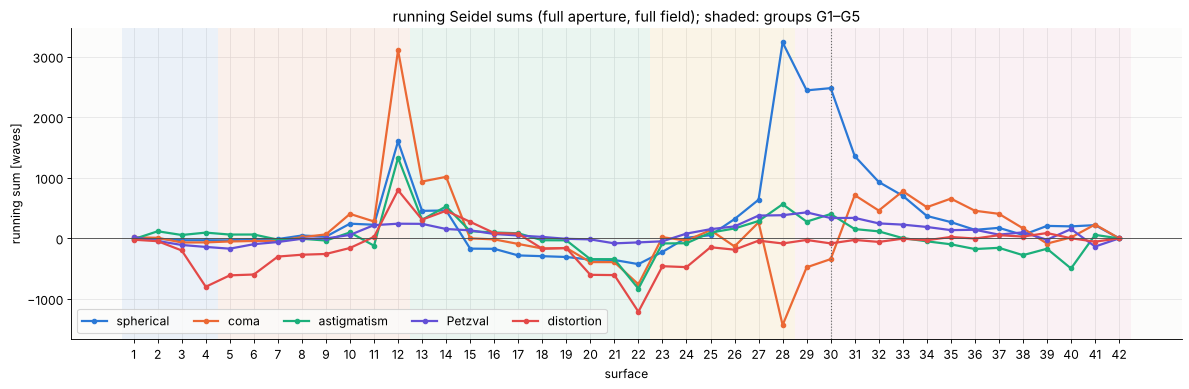

In [7]:
fig, ax = plt.subplots(figsize=(15, 5))
cols = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948"]
for j in range(5):
    ax.plot(idx, np.cumsum(Wsurf[:, j]), "-o", ms=4, lw=2, color=cols[j], label=names[j].split("  ")[0])
ax.axhline(0, color="0.3", lw=0.8)
ax.axvline(lens.stop_index + 1, color="0.4", ls=":", lw=1)
for g, (name, e0, e1) in enumerate(GROUPS):
    ax.axvspan(els[e0][0] + 0.5, els[e1][1] + 1.5, color=COLORS[g], alpha=0.08, lw=0)
ax.set_xlabel("surface")
ax.set_ylabel("running sum [waves]")
ax.set_xticks(idx)
ax.legend(ncol=5, loc="lower left")
ax.set_title("running Seidel sums (full aperture, full field); shaded: groups G1–G5")
fig.tight_layout()

## 4. Seidel sums and real rays

The Seidel sums are of the order of a wave, while the real lens is corrected
to a few hundredths of a wave. The residual third order is not a defect of the
design: it is balanced against the fifth and higher orders, which a lens with
such large single contributions has in abundance. On axis the third order
spherical aberration $W_{040}\rho^4$ of the Seidel sum is cancelled by higher
orders of the real wavefront:

on axis: Seidel W040 = 0.379 waves; real rays: Z9 = -0.062, Z16 = -0.022 waves (Fringe)


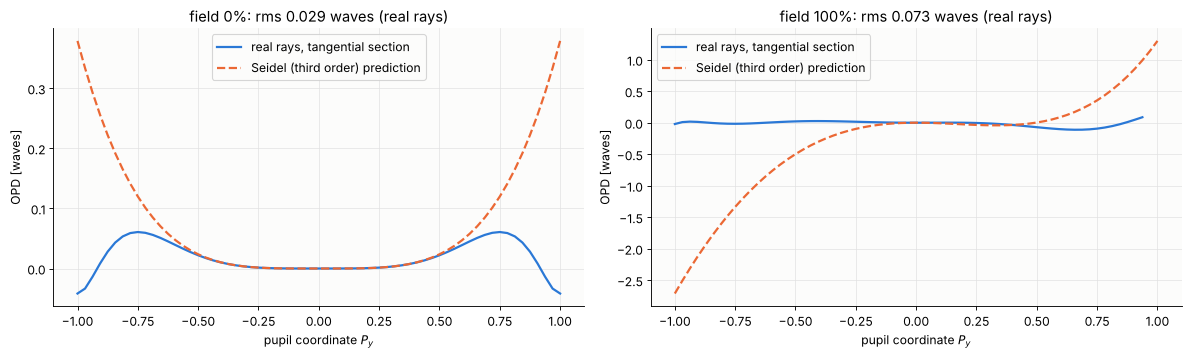

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
rho = np.linspace(0, 1, 101)
for ax, fr in zip(axes, (0.0, 1.0)):
    field = fr*lens.max_field
    m = lens.opd(field, 65)
    W = m.W
    j = np.argmin(abs(m.px))
    ok = np.isfinite(W[:, j])
    ax.plot(m.py[ok], W[ok, j], "-", lw=2, color="#2a78d6", label="real rays, tangential section")
    s_ = lens.seidel(field) if fr > 0 else lens.seidel(1e-9*lens.max_field)
    py = m.py
    W3 = s_.W040*py**4 + s_.W131*py**3 + (s_.W222 + s_.W220)*py**2
    ax.plot(py, W3, "--", lw=2, color="#eb6834",
            label="Seidel (third order) prediction")
    ax.set_xlabel("pupil coordinate $P_y$")
    ax.set_ylabel("OPD [waves]")
    ax.set_title(f"field {fr:.0%}: rms {lens.rms_opd(field):.3f} waves (real rays)")
    ax.legend()
fig.tight_layout()
z = lens.zernike(0.0, n_terms=16)
print(f"on axis: Seidel W040 = {sd.W040:.3f} waves; real rays: Z9 = {z[8]:.3f}, Z16 = {z[15]:.3f} waves (Fringe)")

At the edge of the field the Seidel prediction (spherical aberration, coma,
astigmatism and field curvature; the tilt from distortion is not part of the
OPD) misses the real wavefront by up to 2.7 waves, almost 40 times the real
rms error. In a tense
lens the third order sums are only the starting point. The final balance is
set with real rays (here by Caldwell's optimisation), and the higher orders
are as large as the third.

## 5. Tension: large terms that cancel

A simple measure of the tension of the correction is the ratio of the sum of
the magnitudes of the contributions to the magnitude of their sum. For a relaxed design the ratio is a few.
Here it is in the thousands:

In [9]:
def tension(system):
    s_ = system.seidel()
    return np.abs(s_.S).sum(axis=0)/np.abs(s_.total)

# a relaxed reference: a cemented achromat at F/8, 2 deg field
achromat = rt.System([rt.Surface(61.0, 6.0, material=(1.5168, 64.17), semi_diameter=6.25),
                      rt.Surface(-43.5, 2.5, material=(1.6200, 36.37)),
                      rt.Surface(-130.0, 97.0, n_after=1.0)], 0, 0.55e-3,
                     field_angle=np.radians(2.0)).at_paraxial_focus()
labels = ["S_I", "S_II", "S_III", "S_IV", "S_V"]
print(f"{'':10s}" + "".join(f"{l:>9s}" for l in labels))
print(f"{'achromat':10s}" + "".join(f"{v:9.1f}" for v in tension(achromat)))
print(f"{'Caldwell':10s}" + "".join(f"{v:9.0f}" for v in tension(lens)))

                S_I     S_II    S_III     S_IV      S_V
achromat        4.5      8.3      1.2      1.3     13.7
Caldwell      29444     7652    14108    13479    18836


The sum of the magnitudes of the contributions is what a perturbation sees. A
small error in a surface changes its contributions by a fraction of
themselves, and since the large contributions are no longer balanced, the
change shows up in full. Two examples follow.

**Radius errors.** A relative radius error of $10^{-4}$ on a single surface
(e.g. 8 µm on R = −82 mm) changes the Seidel spherical aberration by up to a
quarter wave:

surface 32: R =   -146.7 mm, y =  80.9 mm, ΔW040 = +0.272 waves
surface 30: R =   -142.5 mm, y =  69.9 mm, ΔW040 = -0.259 waves
surface 14: R =   -156.8 mm, y =  52.6 mm, ΔW040 = -0.153 waves
surface 11: R =    -82.3 mm, y =  34.3 mm, ΔW040 = +0.136 waves
surface 39: R =    109.0 mm, y =  68.8 mm, ΔW040 = -0.130 waves


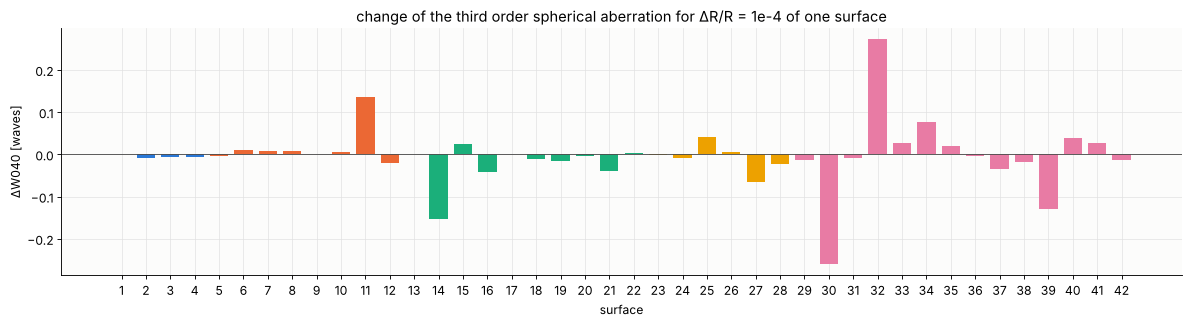

In [10]:
dW040 = np.zeros(n_surf)
for i in range(n_surf):
    other = lens.copy()
    other.surfaces[i].R *= 1 + 1e-4
    dW040[i] = other.seidel().W040 - sd.W040

fig, ax = plt.subplots(figsize=(15, 4.2))
ax.bar(idx, dW040, color=surf_color, width=0.75)
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("surface")
ax.set_ylabel("ΔW040 [waves]")
ax.set_xticks(idx)
ax.set_title("change of the third order spherical aberration for ΔR/R = 1e-4 of one surface")
fig.tight_layout()
for i in np.argsort(-np.abs(dW040))[:5]:
    print(f"surface {i + 1:2d}: R = {lens.surfaces[i].R:8.1f} mm, y = {ym[i]:5.1f} mm, ΔW040 = {dW040[i]:+.3f} waves")

The most sensitive surfaces are not the ones with the largest own terms. They
are the strongly curved surfaces at large ray height: 30 and 32 next to the
stop, 11 in front of the first air lens, and 14 and 39. Changing their radius
changes their power, so the marginal ray reaches every following surface at a
slightly different height and angle. All the large terms downstream, up to
2600 waves each, then change by a small fraction, and the fractions no longer
cancel. In a relaxed lens the same small fractions of small terms would not
matter.

**Decentred elements.** A decentred surface is the centred surface turned
about its centre of curvature. For the axial beam it acts as if it had a
field: the axis ray meets it at the height $\bar y = -\delta$ relative to its
own axis, so $\bar A = -n c\,\delta$. By $S_{II} = (\bar A/A) S_I$ the surface
converts part of its *own* spherical aberration into coma on axis, which no
other surface compensates (Hopkins and Tiziani 1966). Each element decentred
by 5 µm, traced with real rays, and the local estimate
$\Delta W_{131} = S_I\,n c\,\delta/(2A)$ summed over the element's surfaces:

element 15 (surfaces 29-30): -0.394 waves coma per 5 µm
element 16 (surfaces 31-32): +0.372 waves coma per 5 µm
element 17 (surfaces 33-34): +0.307 waves coma per 5 µm
element 14 (surfaces 27-28): -0.277 waves coma per 5 µm


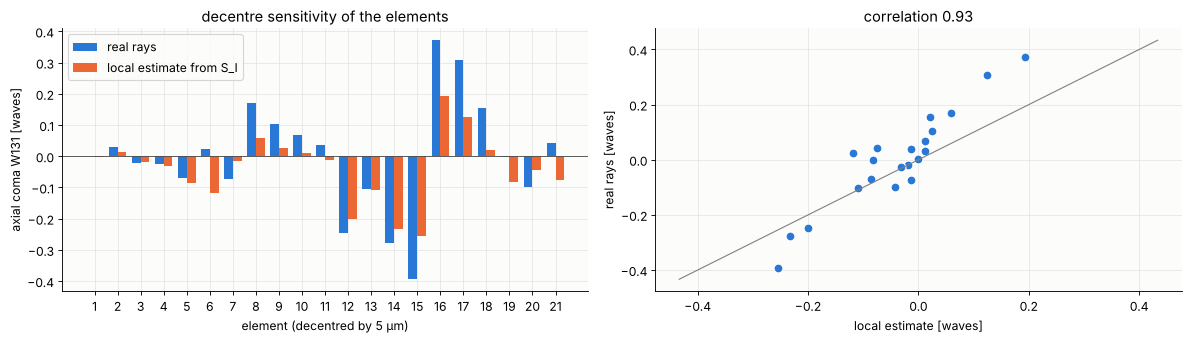

In [11]:
delta = 0.005  # mm
z0_ = lens.zernike(0.0, n_terms=9)
coma_real = np.zeros(len(els))
for k, (a, b) in enumerate(els):
    other = lens.copy()
    for i in range(a, b + 1):
        other.surfaces[i].decenter = (0.0, delta)
    coma_real[k] = 3*(other.zernike(0.0, n_terms=9)[7] - z0_[7])  # W131 = 3*Z8 (Fringe)

n_s = lens.n*lens.sigma
(_, u0), _ = lens._paraxial_rays()
u_in = np.concatenate([[u0], p.marginal[:-1, 1]])
coma_est = np.zeros(len(els))
for k, (a, b) in enumerate(els):
    for i in range(a, b + 1):
        c = lens.surfaces[i].c
        A = n_s[i]*(u_in[i] + ym[i]*c)
        coma_est[k] += sd.S[i, 0]*n_s[i]*c*delta/(2*A)/WL

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
w = 0.38
axes[0].bar(e_idx - w/2, coma_real, w, color="#2a78d6", label="real rays")
axes[0].bar(e_idx + w/2, coma_est, w, color="#eb6834", label="local estimate from S_I")
axes[0].axhline(0, color="0.3", lw=0.8)
axes[0].set_xticks(e_idx)
axes[0].set_xlabel("element (decentred by 5 µm)")
axes[0].set_ylabel("axial coma W131 [waves]")
axes[0].legend()
axes[0].set_title("decentre sensitivity of the elements")
axes[1].plot(coma_est, coma_real, "o", ms=8, color="#2a78d6", mec="white")
lim = 1.1*np.max(np.abs(np.r_[coma_real, coma_est]))
axes[1].plot([-lim, lim], [-lim, lim], color="0.5", lw=1)
axes[1].set_xlabel("local estimate [waves]")
axes[1].set_ylabel("real rays [waves]")
axes[1].set_title(f"correlation {np.corrcoef(coma_est, coma_real)[0, 1]:.2f}")
fig.tight_layout()
for k in np.argsort(-np.abs(coma_real))[:4]:
    a, b = els[k]
    print(f"element {k + 1:2d} (surfaces {a + 1}-{b + 1}): {coma_real[k]:+.3f} waves coma per 5 µm")

The estimate explains most of the real result. It leaves out that the beam
leaving a decentred element is tilted and meets the following surfaces
slightly off axis, which roughly doubles the coma of elements 16 to 18. The
elements around the second air lens and the stop (12, 14, 15, 16, 17), which
carry the largest spherical aberration terms, have to be centred best: 5 µm
give 0.25 to 0.4 waves of coma, several times the whole design residual. This is what the tension of a correction costs, and why lithography
lenses are built with micrometre centring, adjusted on the assembled lens,
and corrected afterwards with manipulator and compensator elements.

Lowering the tension (more elements, aspheres, a less extreme form) is a design
goal in its own right. Desensitised lens design adds the sum of magnitudes, or
directly the decentre sensitivities, to the merit function.

## 6. Colour: what one glass cannot correct

For a thin lens, $C_I = y^2\varphi/V$: axial colour has the sign of the power
and grows with $y^2$. In an all fused silica lens every element has the same
$V$, and the positive groups that make the power are also the ones at large
$y$. The waists cannot cancel the colour as they cancel the Petzval sum.
`chromatic_seidel()` gives the terms for a band of 1 pm:

axial colour -241 nm per pm, lateral colour -11.8 nm per pm at the edge of the field
tension of C_I: 2.6, of C_II: 14.6


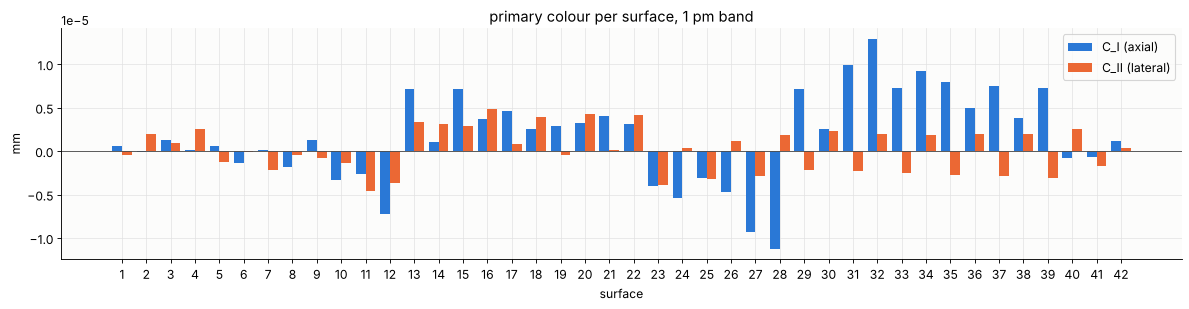

In [12]:
dl = 1e-9  # 1 pm in mm
cs = lens.chromatic_seidel(dl)
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(idx - 0.2, cs.C[:, 0], 0.4, color="#2a78d6", label="C_I (axial)")
ax.bar(idx + 0.2, cs.C[:, 1], 0.4, color="#eb6834", label="C_II (lateral)")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xticks(idx)
ax.set_xlabel("surface")
ax.set_ylabel("mm")
ax.legend()
ax.set_title("primary colour per surface, 1 pm band")
fig.tight_layout()
print(f"axial colour {1e6*cs.axial:.0f} nm per pm, lateral colour {1e6*cs.lateral:.1f} nm per pm at the edge of the field")
print(f"tension of C_I: {np.abs(cs.C[:, 0]).sum()/abs(cs.total[0]):.1f}, of C_II: {np.abs(cs.C[:, 1]).sum()/abs(cs.total[1]):.1f}")

The axial colour of about 0.24 µm per pm is uncorrected. Its tension is only
2.6, because the negative elements cancel less than half of what the positive
ones add. The depth of focus is
$\lambda/\mathrm{NA}^2 \approx 0.8$ µm, so the laser has to be line narrowed to
a fraction of a picometre. The lateral colour, which changes
sign with $\bar y$, is balanced between front and rear (the symmetry principle
again) and stays small.

## Summary

- The pyoptics `System` computes the Seidel terms of every surface, their
  wavefront coefficients and their aspheric parts (`seidel()`), the powers of
  the lens, surfaces and elements (`power()`, `surface_powers()`,
  `element_powers()`), the share of each surface in the power
  (`power_contributions()`), the Petzval sum and the third order image surfaces
  and distortion (`third_order()`), and the primary colour
  (`chromatic_seidel()`).
- In Caldwell's lens the positive groups produce the power and the
  undercorrected spherical aberration. The negative waists flatten the field
  (Petzval sum). The two air lenses behind the strongest negative elements
  (surfaces 12/13 and 28/29), where the marginal ray is steepest, provide the
  overcorrection that balances the spherical aberration. Coma, distortion and lateral colour are balanced
  across the stop. Distortion is controlled mostly by the front groups G1 and
  G2, where the chief ray is high.
- The correction is tense: the terms are thousands of times larger than their
  sums, and the third order residuals are balanced against higher orders. The
  same large terms make the lens sensitive to radius errors and decentres
  (up to 0.4 waves of coma from a 5 µm decentre of one element).
- Axial colour cannot be corrected with one glass: 0.24 µm per pm.

In [13]:
print(f"run time {time.time() - t_start:.0f} s")

run time 8 s


## References

- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986) (Seidel sums, Petzval surface, primary colour).
- R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed., Academic Press (2010) (thin lens contributions, symmetry principle).
- H. H. Hopkins, *Wave Theory of Aberrations*, Clarendon Press (1950).
- H. H. Hopkins and H. J. Tiziani, "A theoretical and experimental study of lens centring errors and their influence on optical image quality", Br. J. Appl. Phys. 17, 33-54 (1966).
- J. B. Caldwell, "All-fused-silica 248-nm lithographic projection lens", Optics & Photonics News 9(11), 40-41 (1998).
- T. Matsuyama, Y. Ohmura and D. M. Williamson, "The lithographic lens: its history and evolution", Proc. SPIE 6154, 615403 (2006).